In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("data.csv")
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.rename(columns={"observation_date": "date", "IPG2211A2N": "value"})
df = df.set_index("date").sort_index()
df

,value
date,
1939-01-01,3.3336
1939-02-01,3.3591
1939-03-01,3.4354
1939-04-01,3.4608
1939-05-01,3.4608
...,...
2025-11-01,101.4705
2025-12-01,121.2860
2026-01-01,130.3652


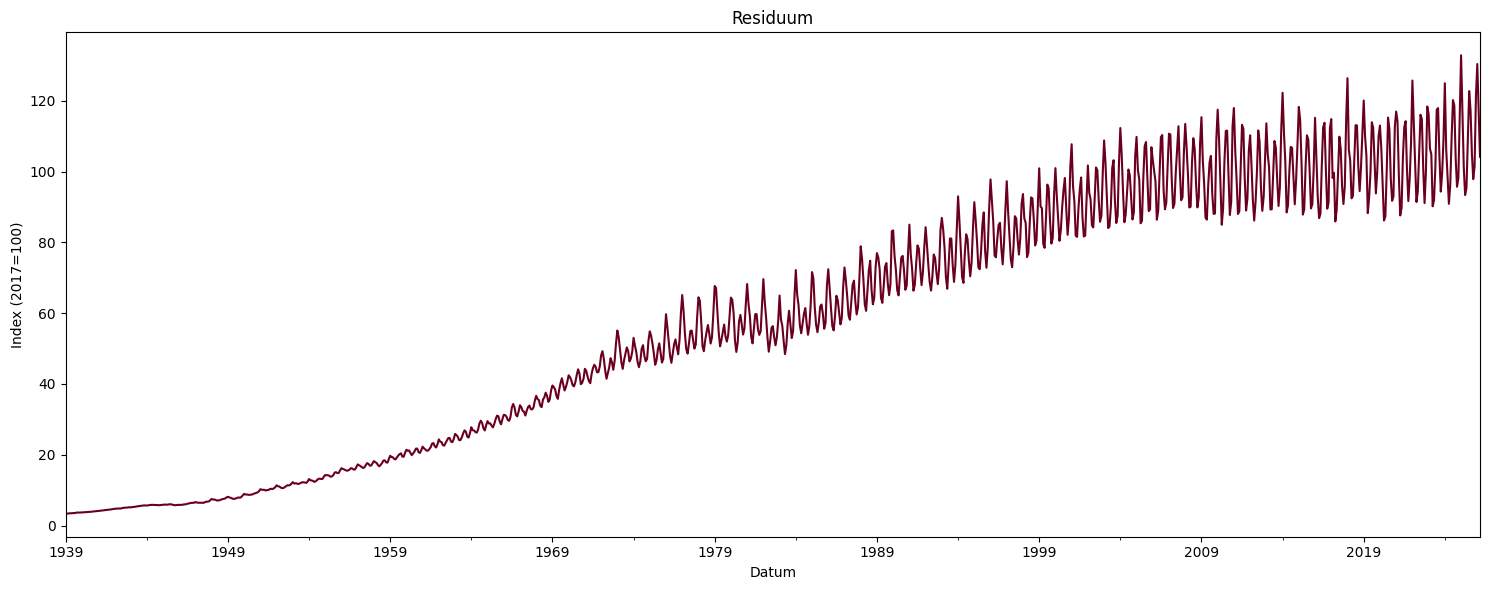

In [3]:
series = df["value"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Residuum",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

## Saisonalität

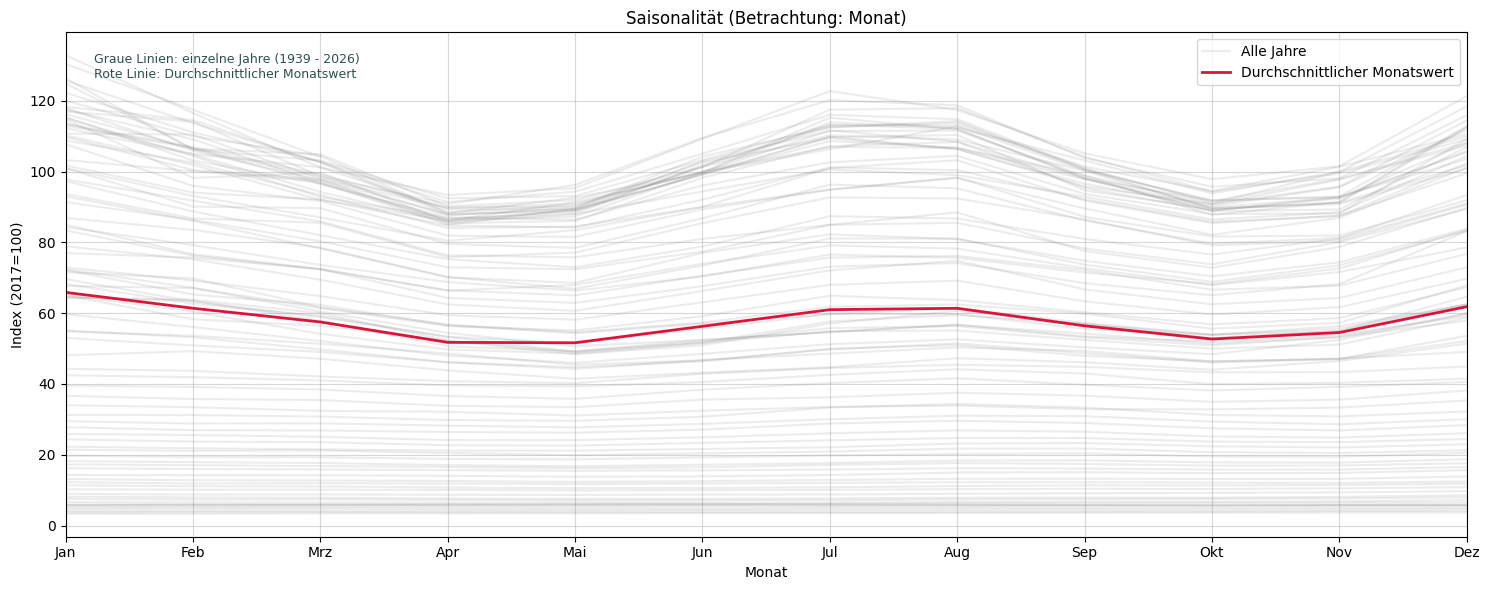

In [4]:
def analyse_seasonality(df: pd.DataFrame, col: str = "value") -> pd.DataFrame:
    df = df.copy()
    df["month"] = df.index.month  # Fokus auf ein Jahr setzen

    # Der Mittelwert aller Monate über alle Jahre
    seasonal = df.groupby("month")[col].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    # Verbrauch aller Jahre zur Veranschaulichung
    df["pivot_year"] = df.index.year
    pivot_data = df.pivot_table(index="month", columns="pivot_year", values=col)

    lines = ax.plot(pivot_data, color="gray", alpha=0.15)
    if lines:
        lines[0].set_label("Alle Jahre")

    seasonal.plot(ax=ax, color="crimson", linewidth=2, label="Durchschnittlicher Monatswert")

    ax.set(
        title="Saisonalität (Betrachtung: Monat)",
        xlabel="Monat",
        ylabel="Index (2017=100)",
    )
    ax.text(
        0.02,
        0.96,
        f"Graue Linien: einzelne Jahre ({pivot_data.columns.min()} - {pivot_data.columns.max()})\nRote Linie: Durchschnittlicher Monatswert",
        transform=ax.transAxes,
        fontsize=9,
        color="darkslategray",
        verticalalignment="top",
    )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()
    plt.tight_layout()
    plt.show()

    df["value_saison"] = df.groupby("month")[col].transform("mean")
    df.drop(columns=["month", "pivot_year"])


analyse_seasonality(df, col="value")

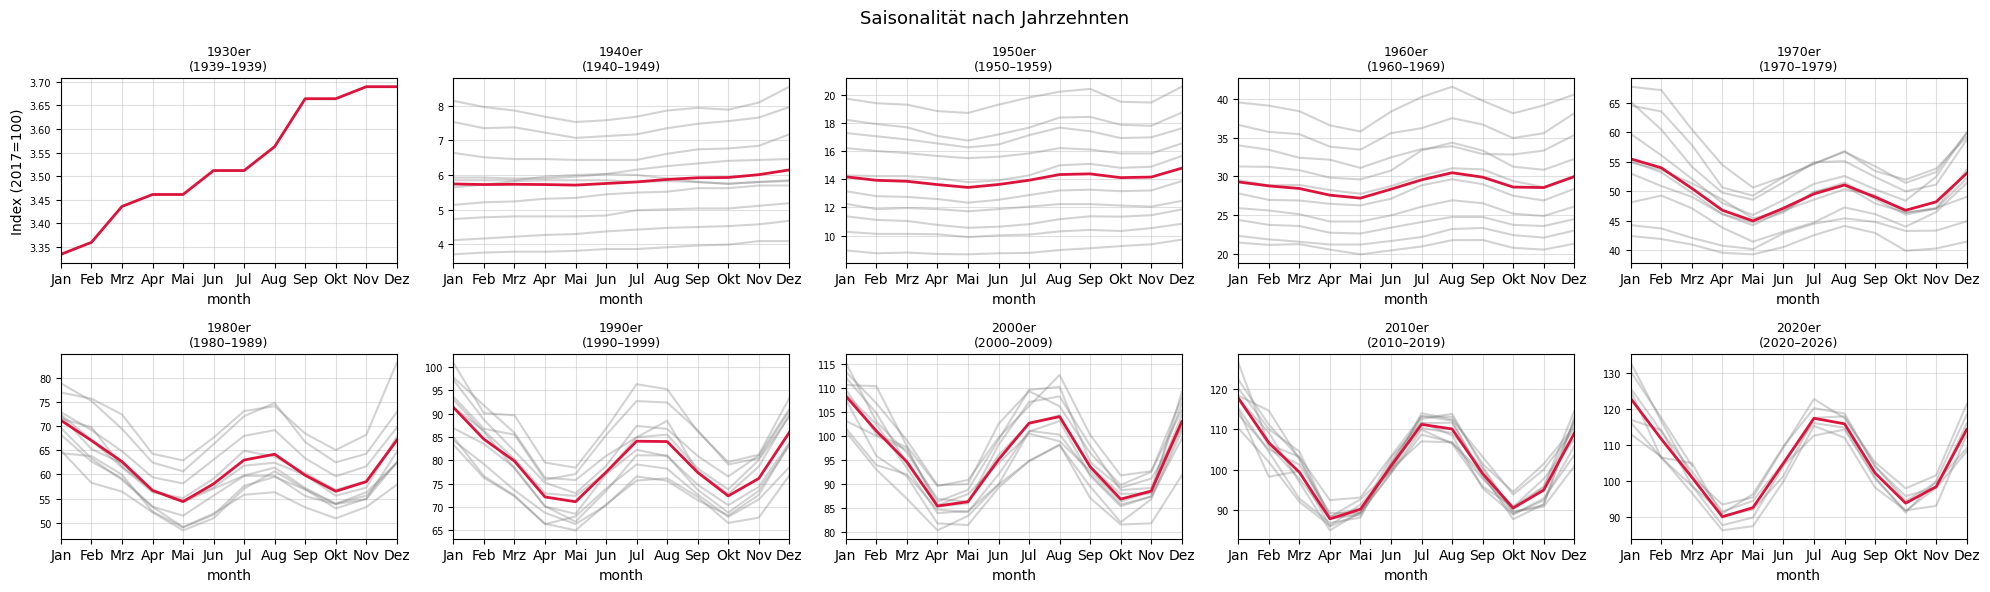

In [5]:
def analyse_seasonality_by_decade(df: pd.DataFrame, col: str = "value") -> None:
    df = df.copy()
    df["month"] = df.index.month
    df["year"] = df.index.year
    df["decade"] = (df["year"] // 10) * 10

    decades = sorted(df["decade"].unique())

    fig, axes = plt.subplots(2, 5, figsize=(20, 6), sharey=False)
    axes = axes.flatten()

    for ax, decade in zip(axes, decades):
        decade_df = df[df["decade"] == decade]
        pivot_data = decade_df.pivot_table(index="month", columns="year", values=col)
        seasonal = decade_df.groupby("month")[col].mean()

        lines = ax.plot(pivot_data, color="gray", alpha=0.35)
        if lines:
            lines[0].set_label("Einzelne Jahre")
        seasonal.plot(ax=ax, color="crimson", linewidth=2, label="Dekadenmittel")

        year_min = decade_df["year"].min()
        year_max = decade_df["year"].max()
        ax.set_title(f"{decade}er\n({year_min}–{year_max})", fontsize=9)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
        ax.grid(axis="both", alpha=0.4)
        ax.margins(x=0)
        ax.tick_params(axis="y", labelsize=7)

    axes[0].set_ylabel("Index (2017=100)")
    fig.suptitle("Saisonalität nach Jahrzehnten", fontsize=13)
    plt.tight_layout()
    plt.show()


analyse_seasonality_by_decade(df, col="value")

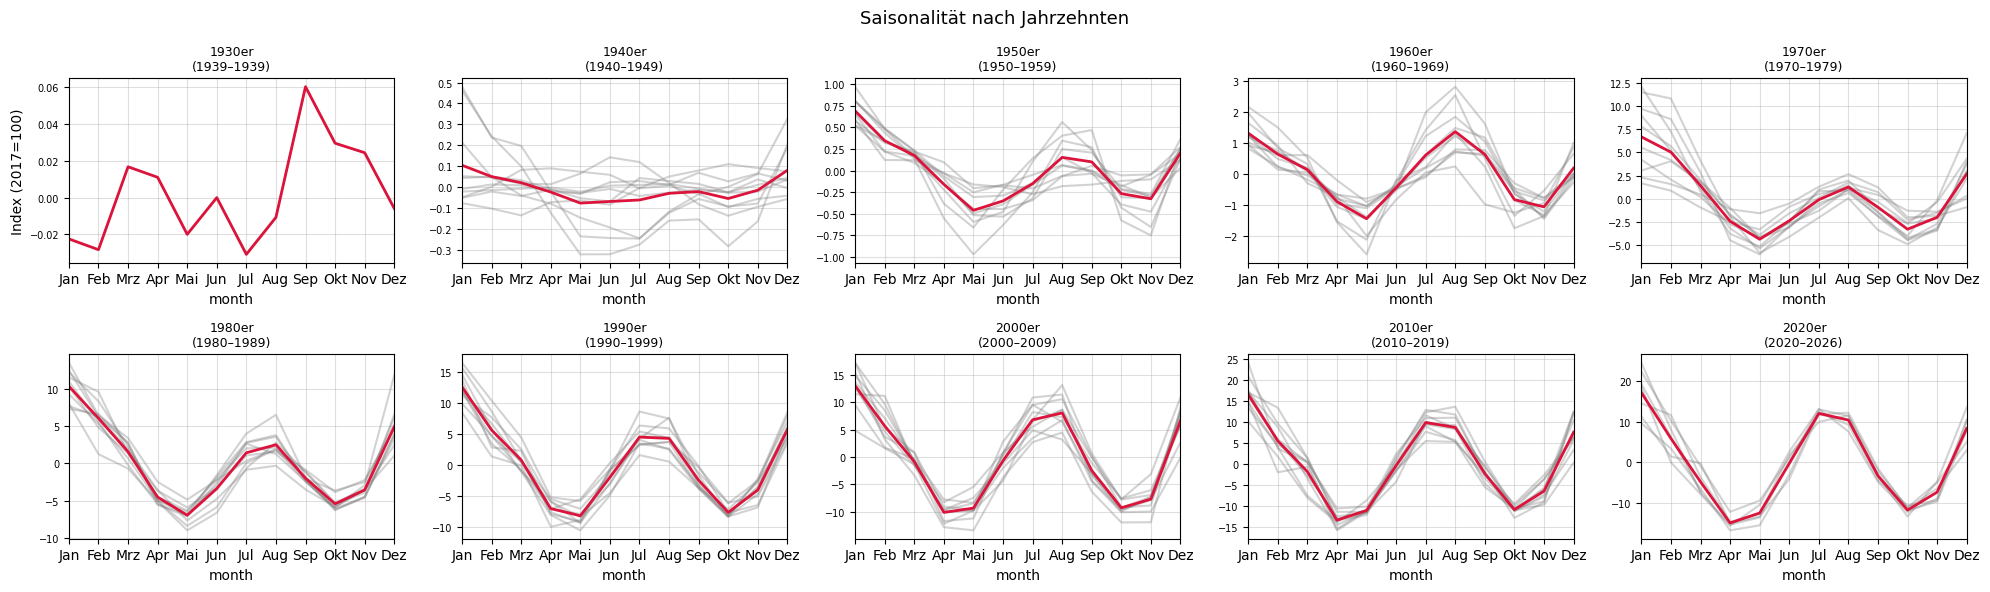

In [6]:
from statsmodels.tsa.seasonal import STL

stl = STL(df["value"], period=12, robust=True)
stl_fit = stl.fit()

df["trend"] = stl_fit.trend
df["value_detrended"] = df["value"] - df["trend"]
analyse_seasonality_by_decade(df, col="value_detrended")

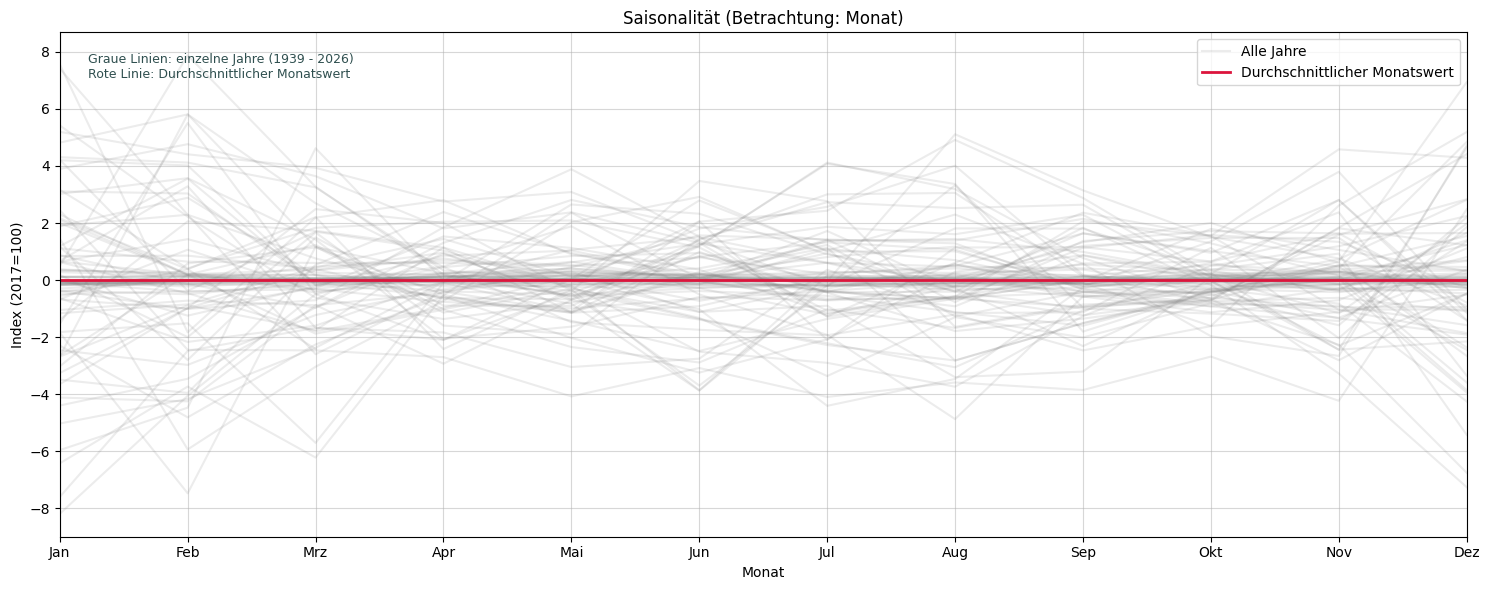

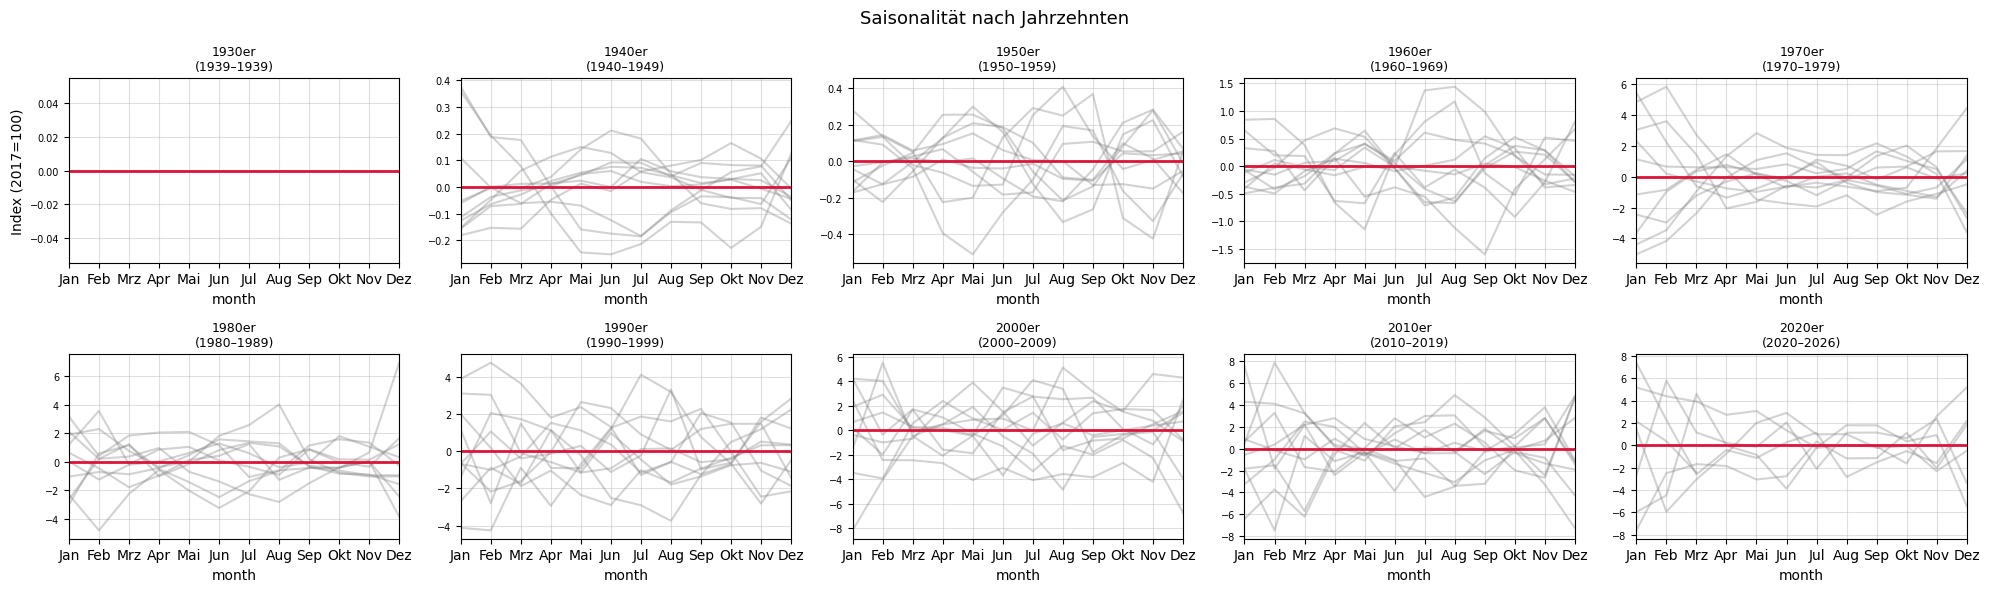

In [7]:
# Hilfsspalten
df["month"] = df.index.month
df["decade"] = (df.index.year // 10) * 10

# Saisonkomponente: Mittelwert je Dekade und Monat (auf der trendbereinigten Reihe)
df["seasonal_decade"] = df.groupby(["decade", "month"])["value_detrended"].transform("mean")

# Residuum
df["residuum"] = df["value_detrended"] - df["seasonal_decade"]

# Hilfsspalten entfernen
df = df.drop(columns=["month", "decade"])
analyse_seasonality(df, col="residuum")
analyse_seasonality_by_decade(df, col="residuum")

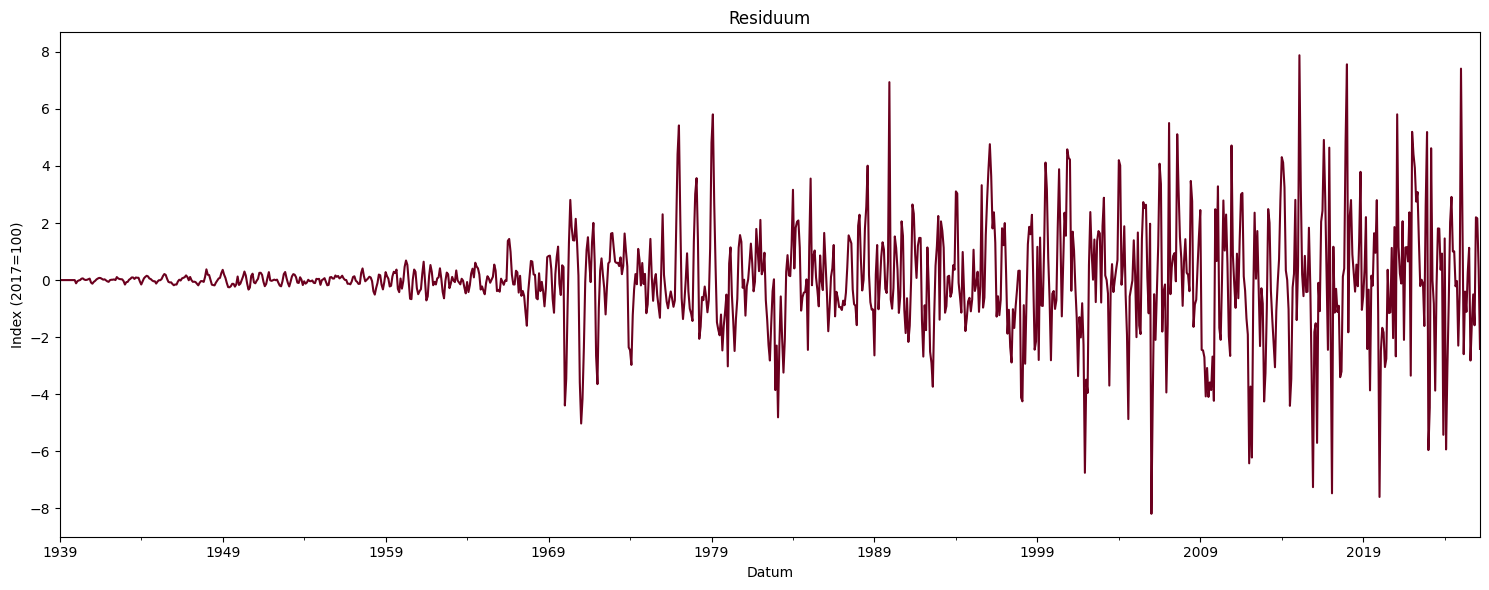

In [8]:
series = df["residuum"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Residuum",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

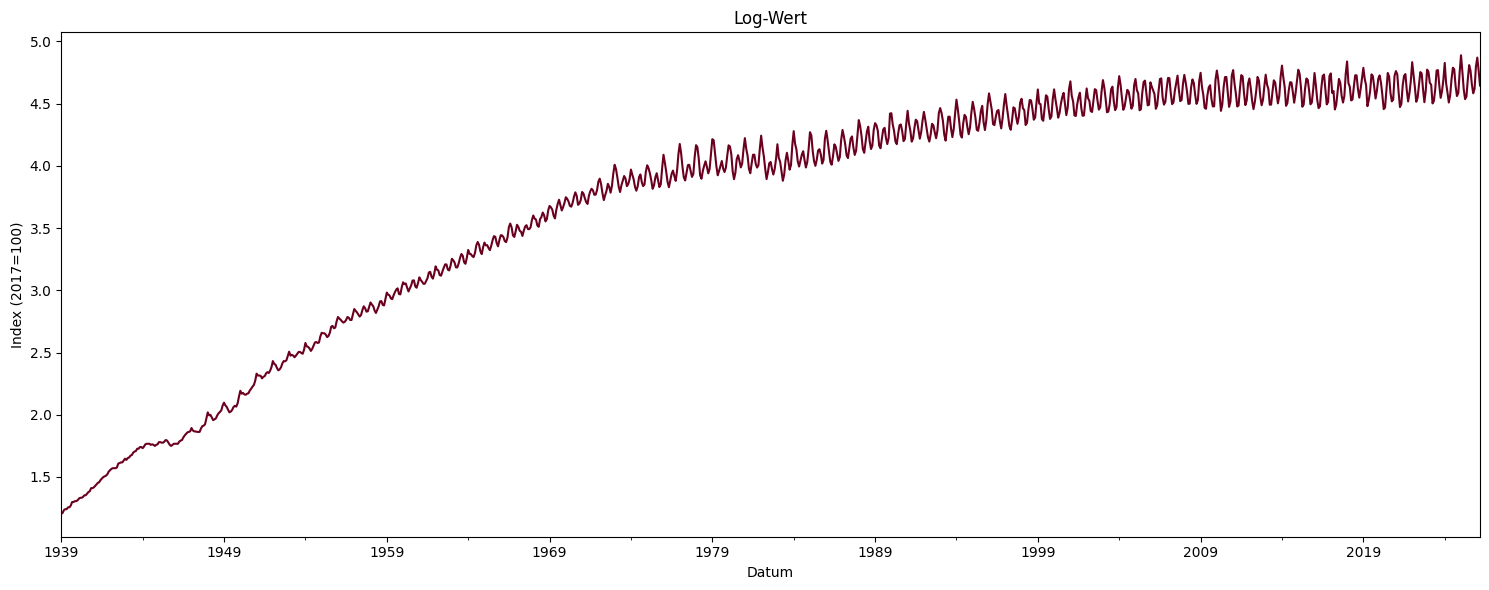

In [9]:
df["value_log"] = np.log(df["value"])
series = df["value_log"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Log-Wert",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

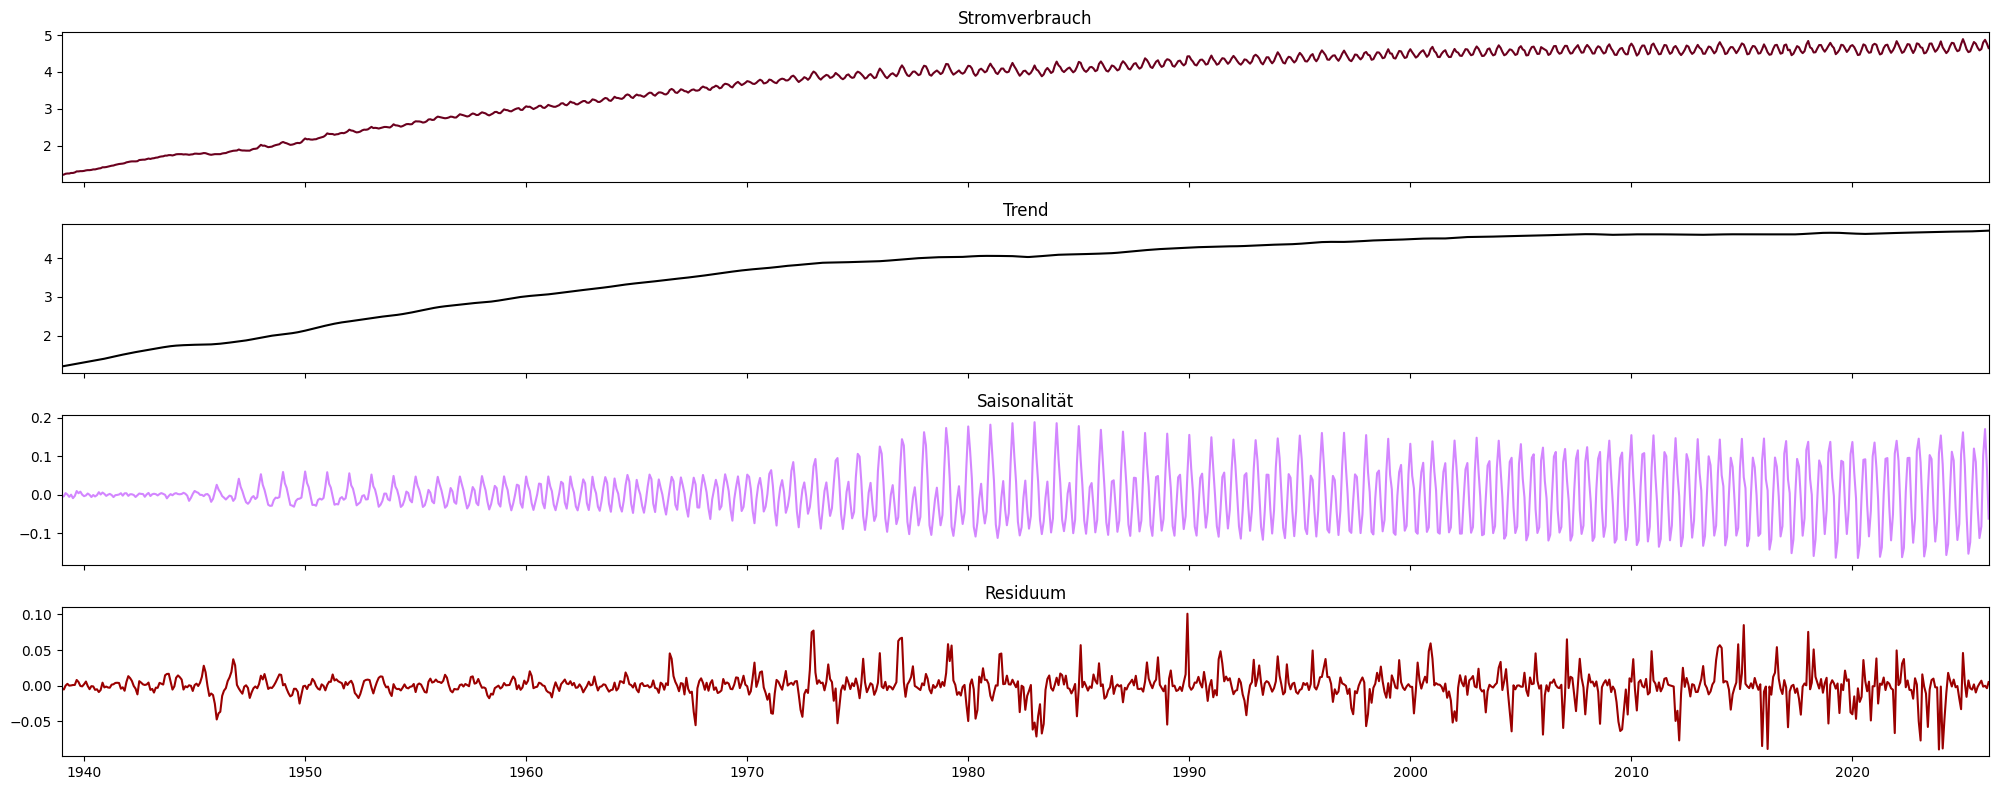

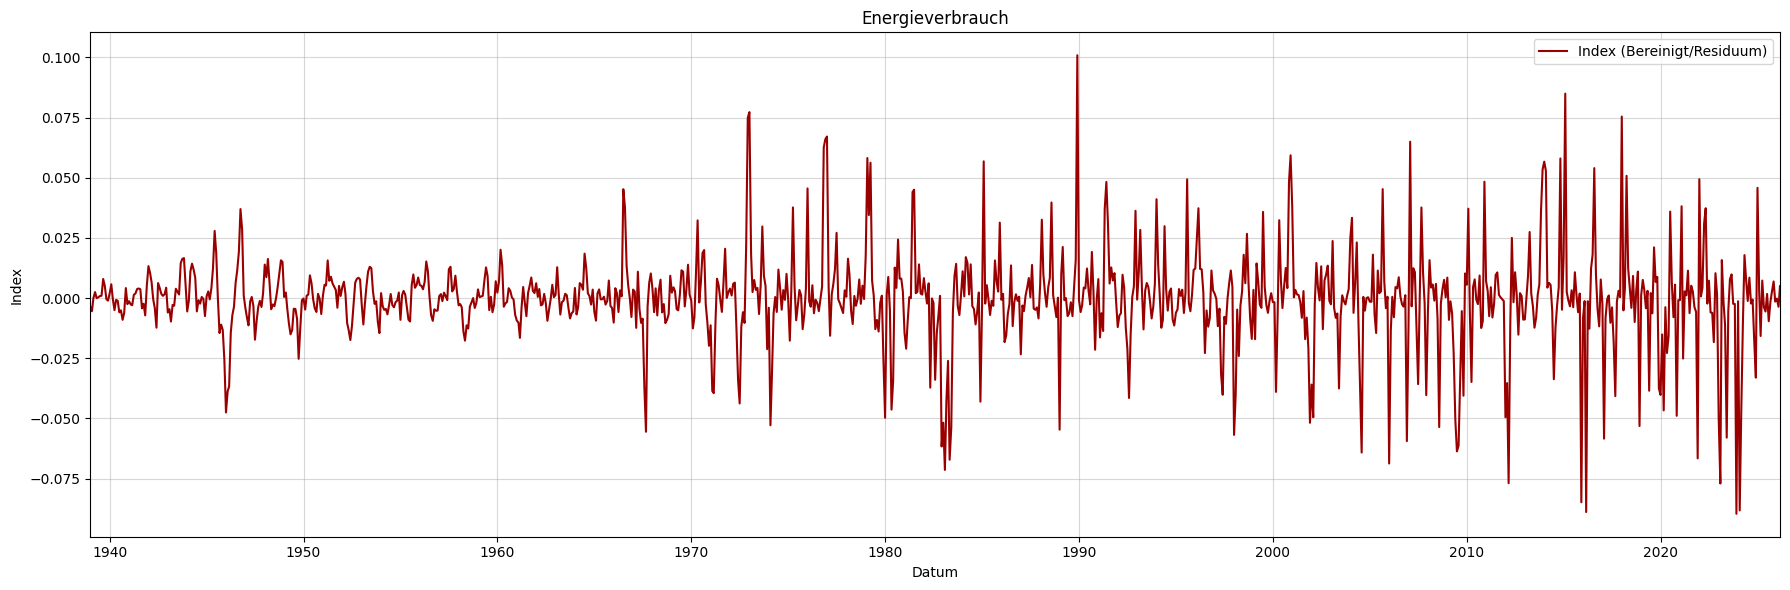

In [10]:
from statsmodels.tsa.seasonal import STL

decomposition = STL(df["value_log"], period=12, robust=True)
decomposition = decomposition.fit()

_, ax = plt.subplots(4, 1, figsize=(20, 8), sharex=True)

ax[0].plot(df["value_log"], color="#6B001E")
ax[0].set_title("Stromverbrauch")

ax[1].plot(decomposition.trend, color="#000000FF")
ax[1].set_title("Trend")

ax[2].plot(decomposition.seasonal, color="#D386FF")
ax[2].set_title("Saisonalität")

ax[3].plot(decomposition.resid, color="#9B0000")
ax[3].set_title("Residuum")

plt.margins(x=0)
plt.tight_layout()
plt.show()

# Residuum der gesamten Zeitreihe
plt.figure(figsize=(18, 6))

plt.plot(df.index, decomposition.resid, color="#9B0000", label="Index (Bereinigt/Residuum)")

plt.title("Energieverbrauch")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

df["log_trend"] = decomposition.trend
df["log_trendbereinigt"] = df["value_log"] - df["log_trend"]
df["log_saison"] = decomposition.seasonal
df["log_residuum"] = decomposition.resid

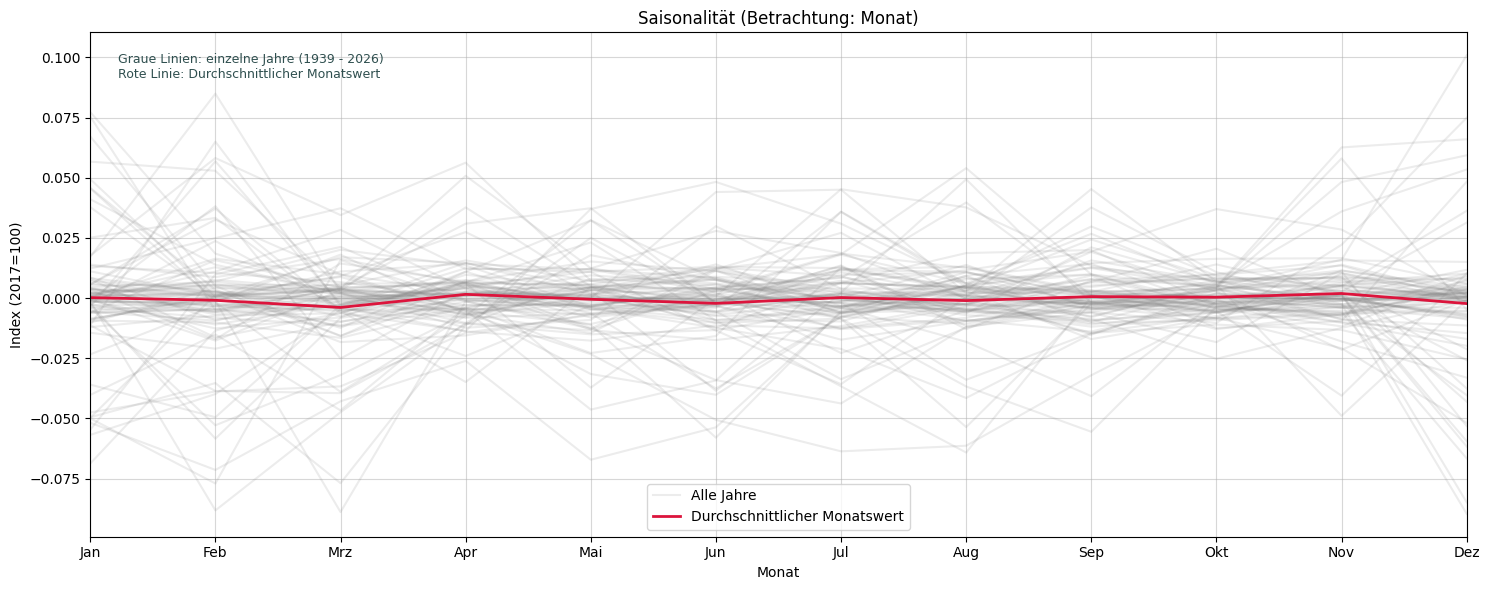

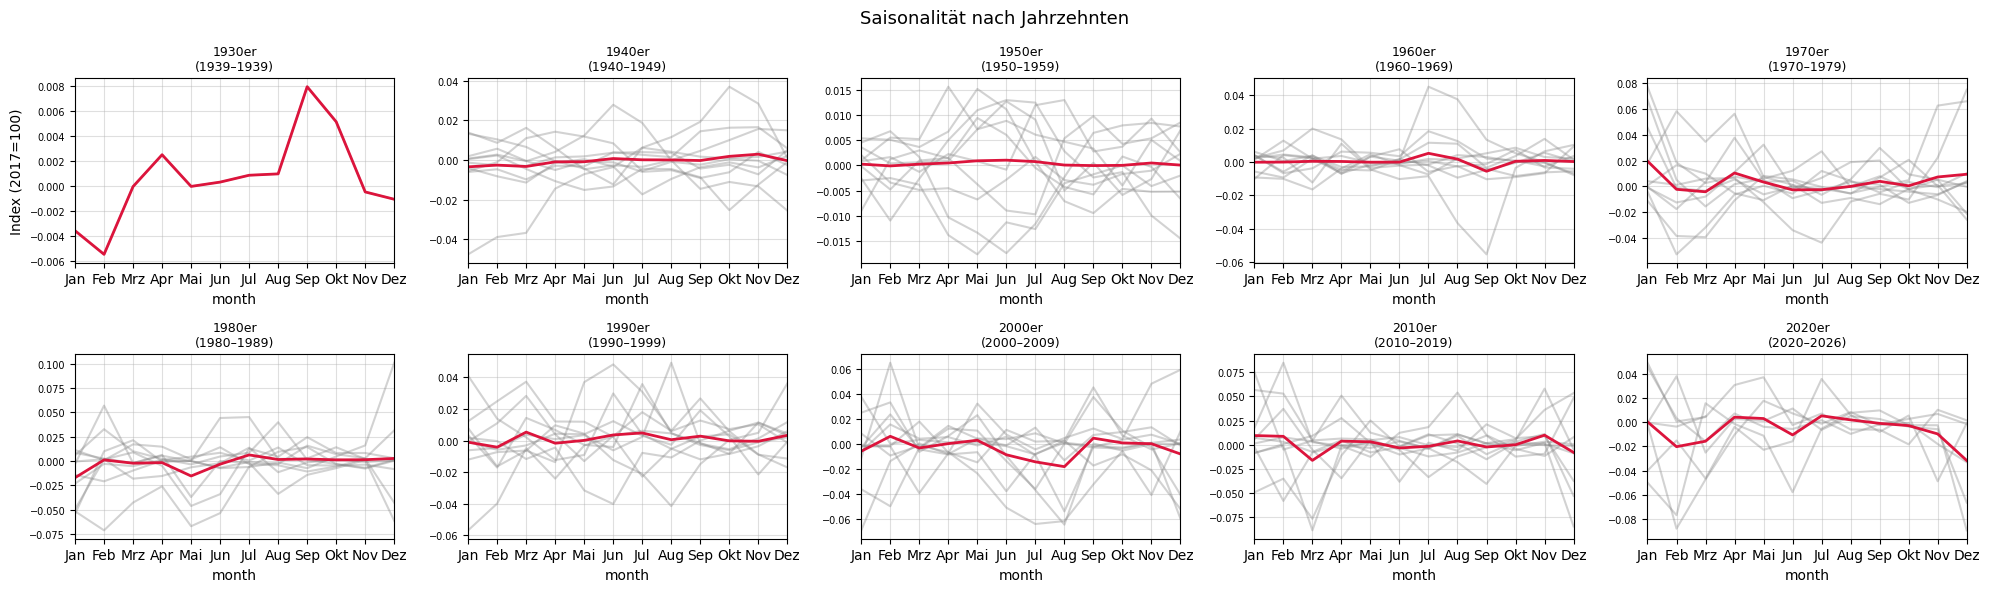

In [11]:
analyse_seasonality(df, col="log_residuum")
analyse_seasonality_by_decade(df, col="log_residuum")

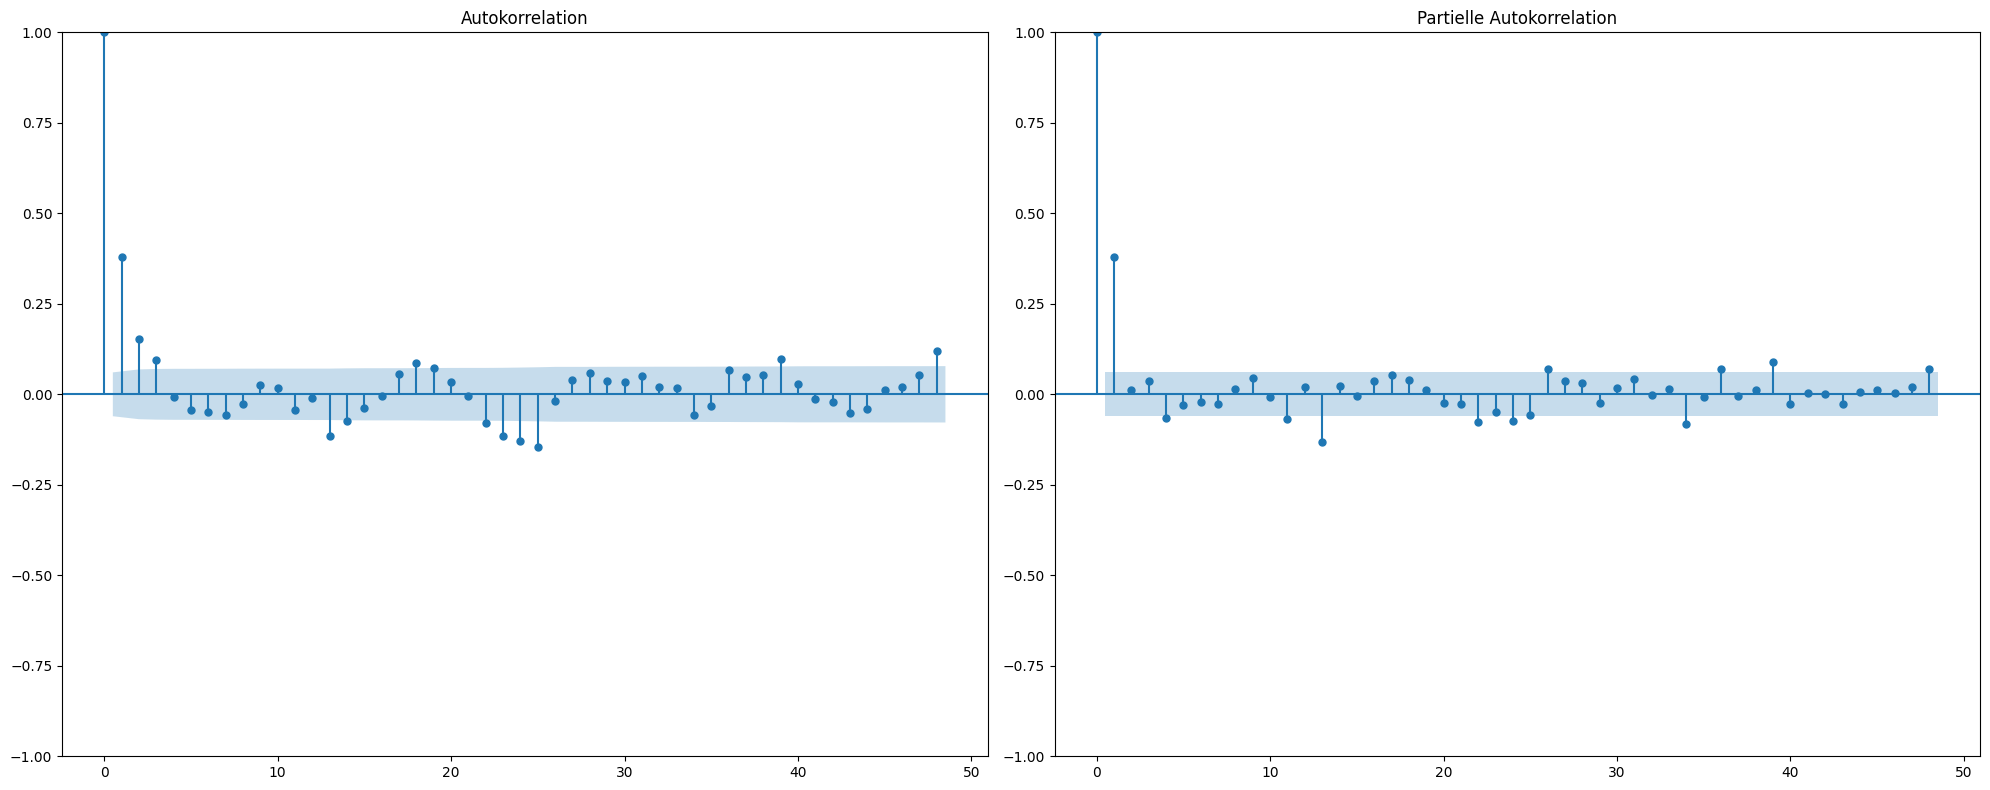

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Autokorrelation
# TODO Lags festlegen / Begründung formulieren
_, ax = plt.subplots(1, 2, figsize=(20, 8))

plot_acf(df["log_residuum"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["log_residuum"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

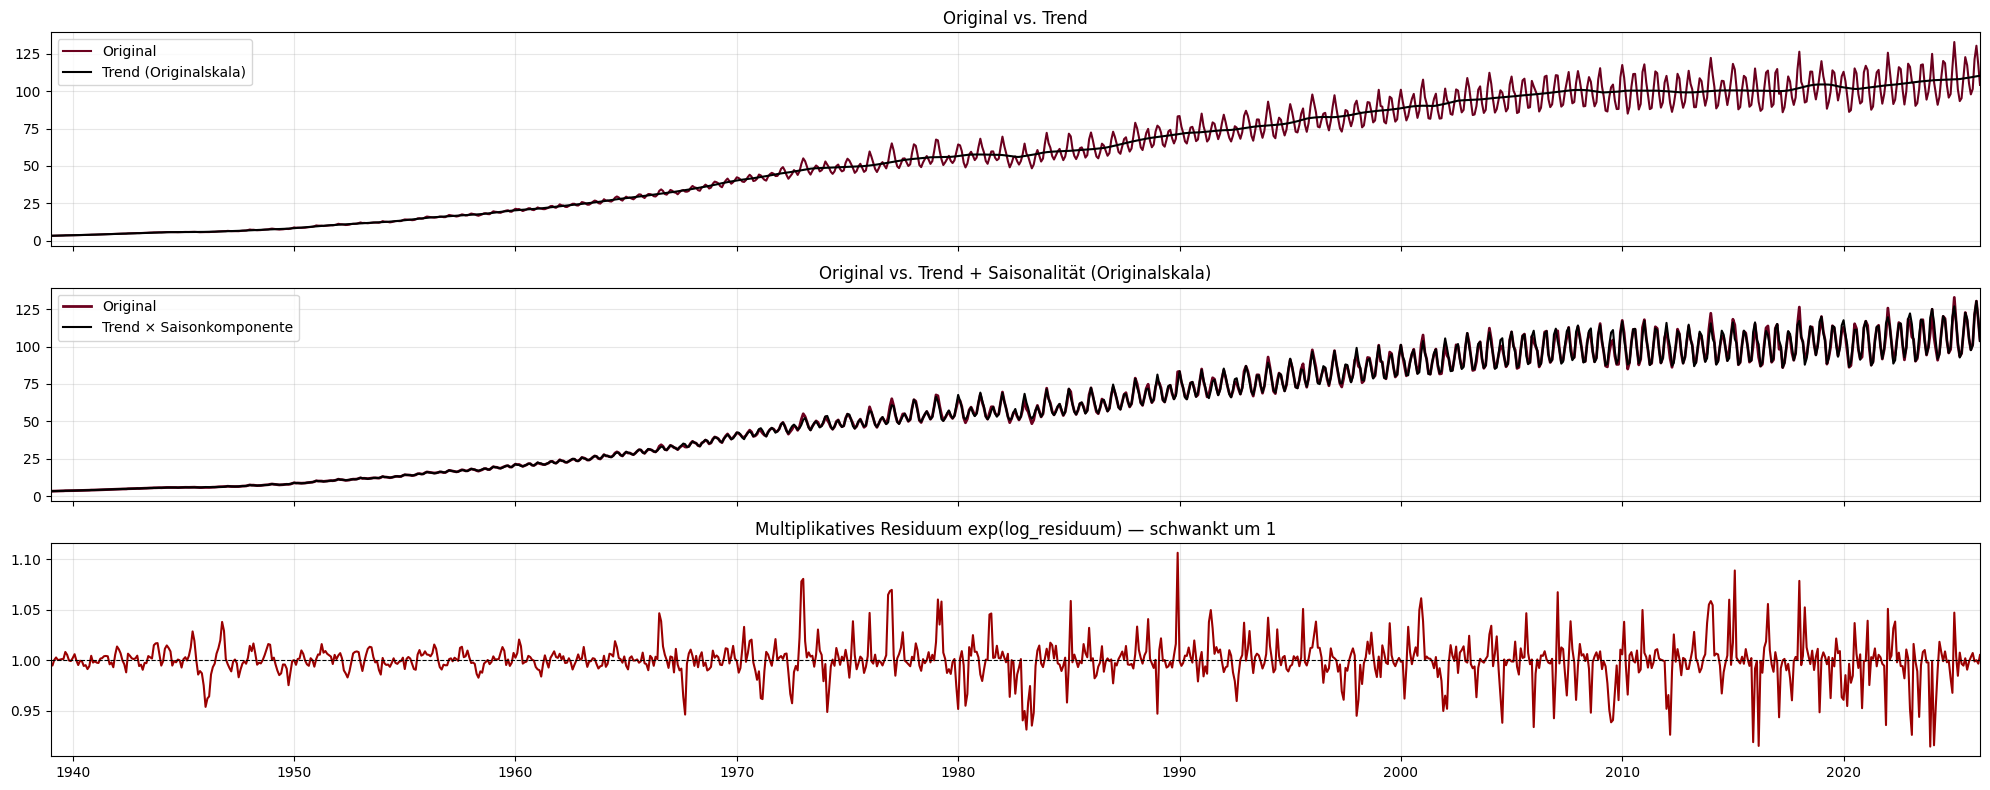

In [13]:
# Rücktransformation in Originalskala
df["trend_orig"] = np.exp(df["log_trend"])
df["saison_factor"] = np.exp(df["log_saison"])  # multiplikativer Saisonfaktor
df["resid_factor"] = np.exp(df["log_residuum"])  # multiplikativer Restfaktor, ≈ 1
df["reconstruction"] = df["trend_orig"] * df["saison_factor"]  # Trend × Saison, ohne Residuum

fig, axes = plt.subplots(3, 1, figsize=(20, 8), sharex=True)

axes[0].plot(df["value"], color="#6B001E", label="Original")
axes[0].plot(df["trend_orig"], color="black", label="Trend (Originalskala)")
axes[0].set_title("Original vs. Trend")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].margins(x=0)

axes[1].plot(df["value"], color="#6B001E", linewidth=2, label="Original")
axes[1].plot(df["reconstruction"], color="black", label="Trend × Saisonkomponente")
axes[1].set_title("Original vs. Trend + Saisonalität (Originalskala)")
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].margins(x=0)

axes[2].plot(df["resid_factor"], color="#9B0000")
axes[2].axhline(1.0, color="black", linewidth=0.8, linestyle="--")
axes[2].set_title("Multiplikatives Residuum exp(log_residuum) — schwankt um 1")
axes[2].grid(alpha=0.3)
axes[2].margins(x=0)

plt.tight_layout()
plt.show()

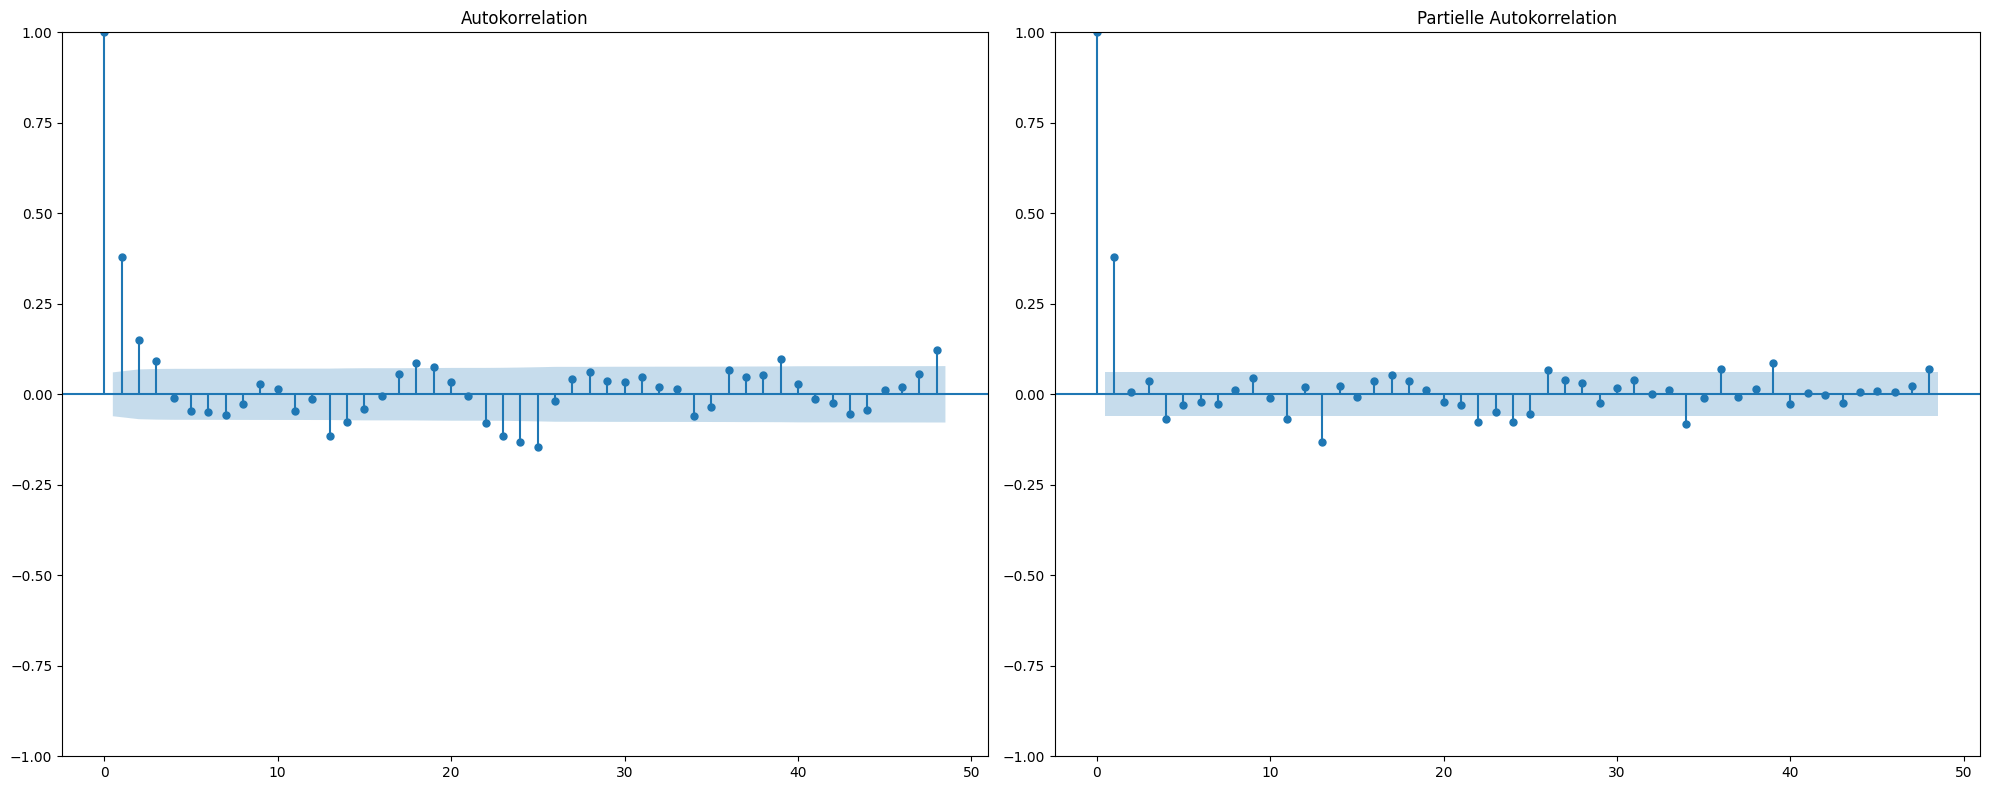

In [14]:
# Autokorrelation
_, ax = plt.subplots(1, 2, figsize=(20, 8))

plot_acf(df["resid_factor"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["resid_factor"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:               residuum   No. Observations:                 1047
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1983.016
Date:                Mon, 11 May 2026   AIC                           3976.032
Time:                        23:48:28   BIC                           4000.796
Sample:                    01-01-1939   HQIC                          3985.423
                         - 03-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5813      0.021    -27.915      0.000      -0.622      -0.540
ar.L2          0.4034      0.020     20.119      0.000       0.364       0.443
ma.L1      -3.392e-05      0.385  -8.82e-05      1.0

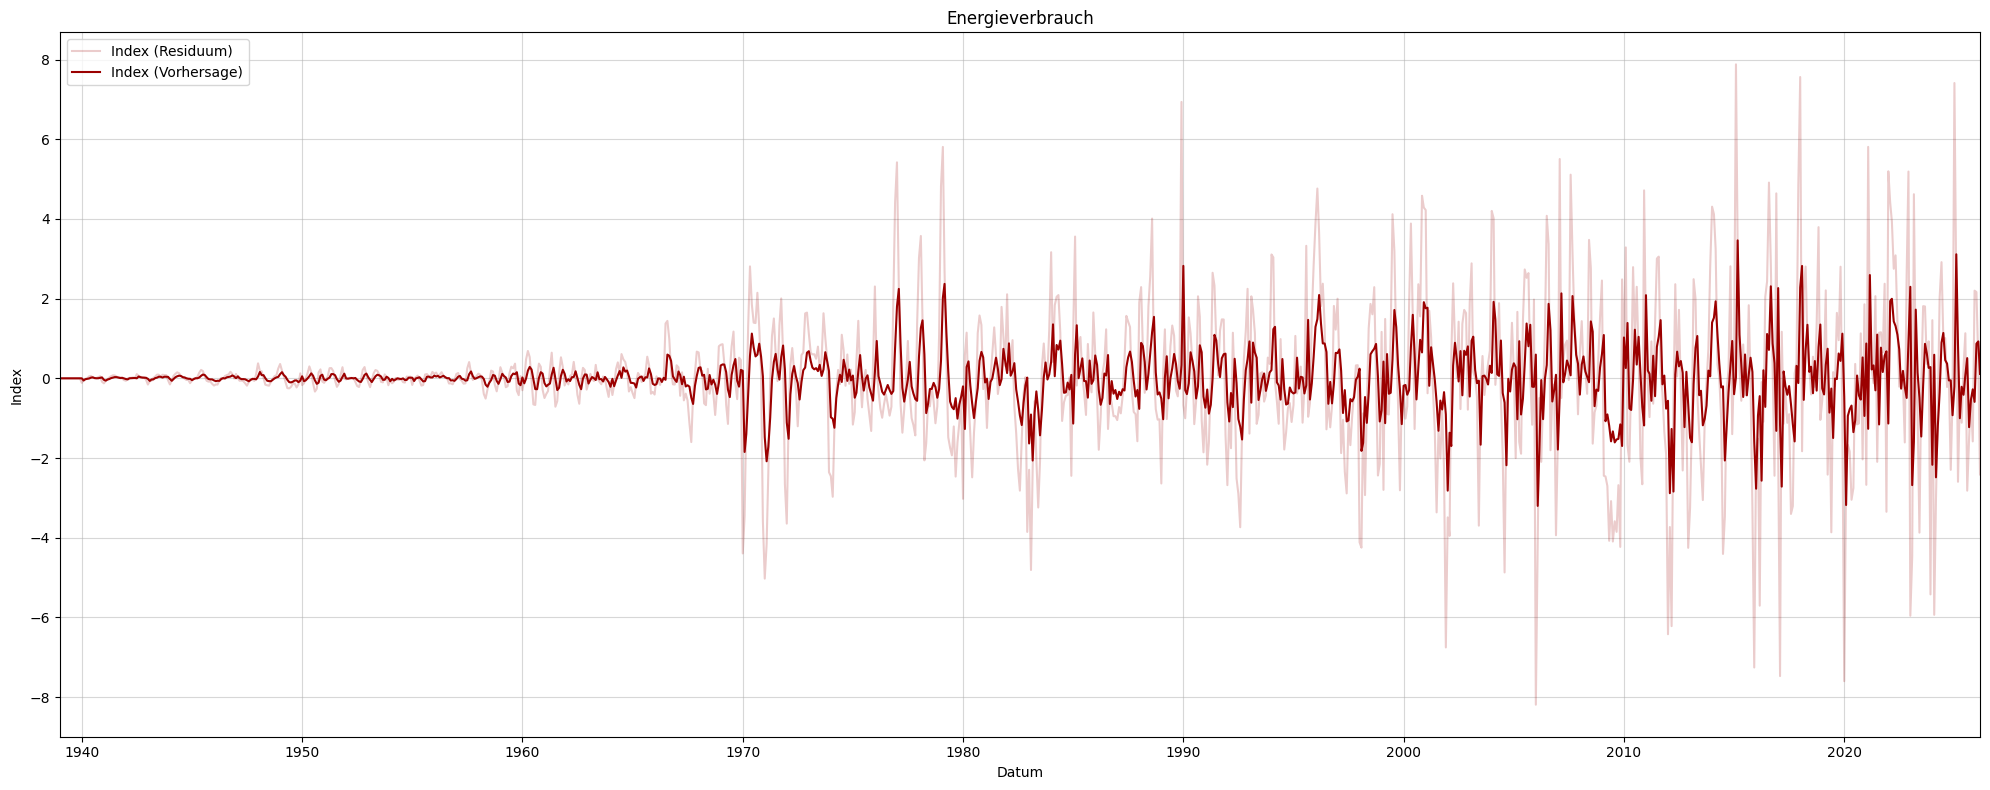

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

time_series = df["residuum"]

# Note: ARMA is a special case of ARIMA where d=0 (no differencing)
# The order (p,d,q) represents (AR order, Differencing order, MA order)
model = ARIMA(time_series, order=(2, 1, 2), freq="MS")  # TODO Werte festlegen
model_fit = model.fit()

print(model_fit.summary())

# Vorhersage
pred = model_fit.predict()

# Metriken
# Hier zu betrachten: MSE
print("MSE:", mean_squared_error(time_series, pred))
print("RMSE:", root_mean_squared_error(time_series, pred))
print("MAE:", mean_absolute_error(time_series, pred))
print("R2:", r2_score(time_series, pred))

# Darstellung
plt.figure(figsize=(20, 8))

plt.plot(df.index, df["residuum"], color="#9B0000", alpha=0.2, label="Index (Residuum)")
plt.plot(df.index, pred, color="#9B0000", label="Index (Vorhersage)")

plt.title("Energieverbrauch")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
time_series = df["log_residuum"].dropna()

# Kandidaten aus ACF/PACF: PACF bricht nach Lag 1 ab → p=1, d=0
# ACF zeigt Lags 1-2 signifikant → q=1 oder q=2
candidates = [(1, 0, 0), (1, 0, 1), (1, 0, 2)]
results = {}

for order in candidates:
    fit  = ARIMA(time_series, order=order).fit()
    pred = fit.predict()
    results[order] = {
        "fit":  fit,
        "pred": pred,
        "MSE":  mean_squared_error(time_series, pred),
        "RMSE": root_mean_squared_error(time_series, pred),
        "MAE":  mean_absolute_error(time_series, pred),
        "R2":   r2_score(time_series, pred),
        "AIC":  fit.aic,
        "BIC":  fit.bic,
    }

# Übersichtstabelle
print(f"{'Modell':<15} {'MSE':>10} {'RMSE':>10} {'MAE':>10} {'R²':>8} {'AIC':>10} {'BIC':>10}")
print("-" * 73)
for order, r in results.items():
    print(f"ARIMA{str(order):<10} {r['MSE']:>10.6f} {r['RMSE']:>10.6f} "
          f"{r['MAE']:>10.6f} {r['R2']:>8.4f} {r['AIC']:>10.2f} {r['BIC']:>10.2f}")

/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026

Modell                 MSE       RMSE        MAE       R²        AIC        BIC
-------------------------------------------------------------------------
ARIMA(1, 0, 0)    0.000320   0.017886   0.011105   0.1441   -5448.25   -5433.39
ARIMA(1, 0, 1)    0.000320   0.017885   0.011117   0.1442   -5446.41   -5426.59
ARIMA(1, 0, 2)    0.000320   0.017882   0.011119   0.1444   -5444.71   -5419.94


/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/patrick/hka/SS2026/DABI2/Projekt/DABI-2/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


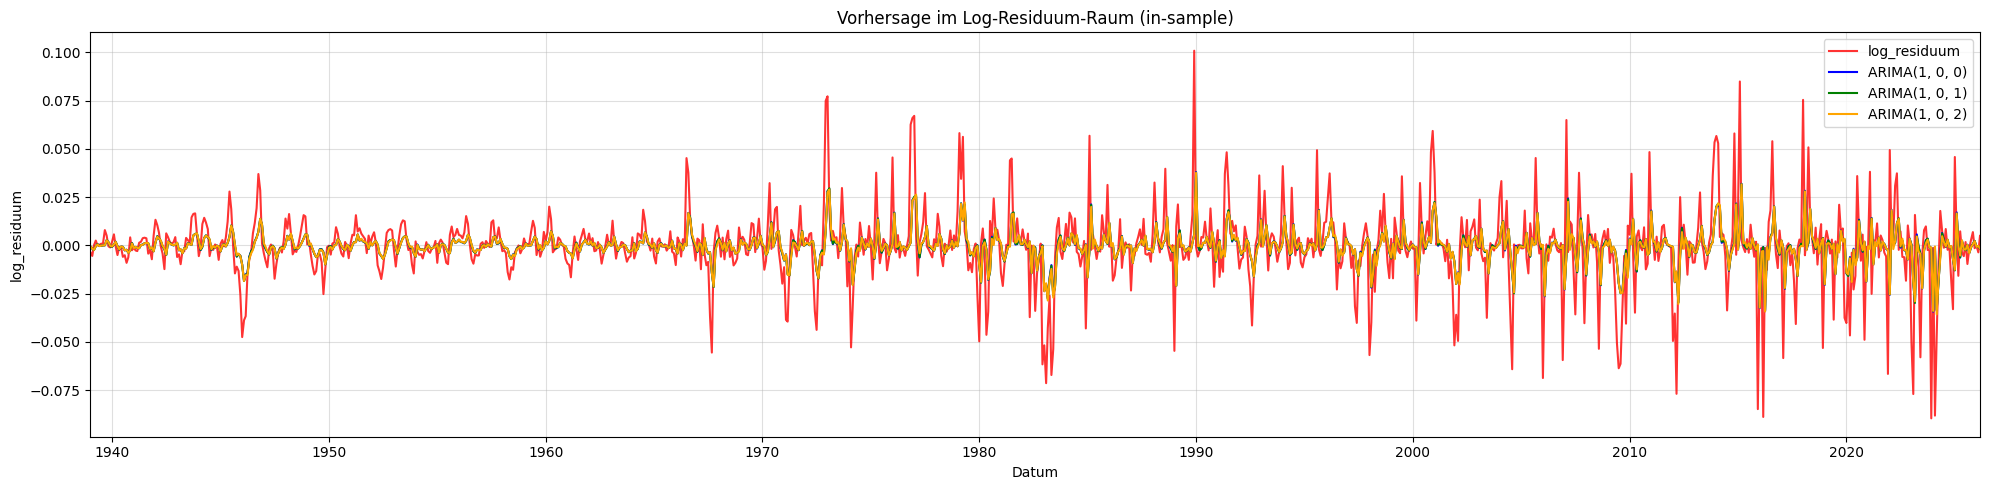

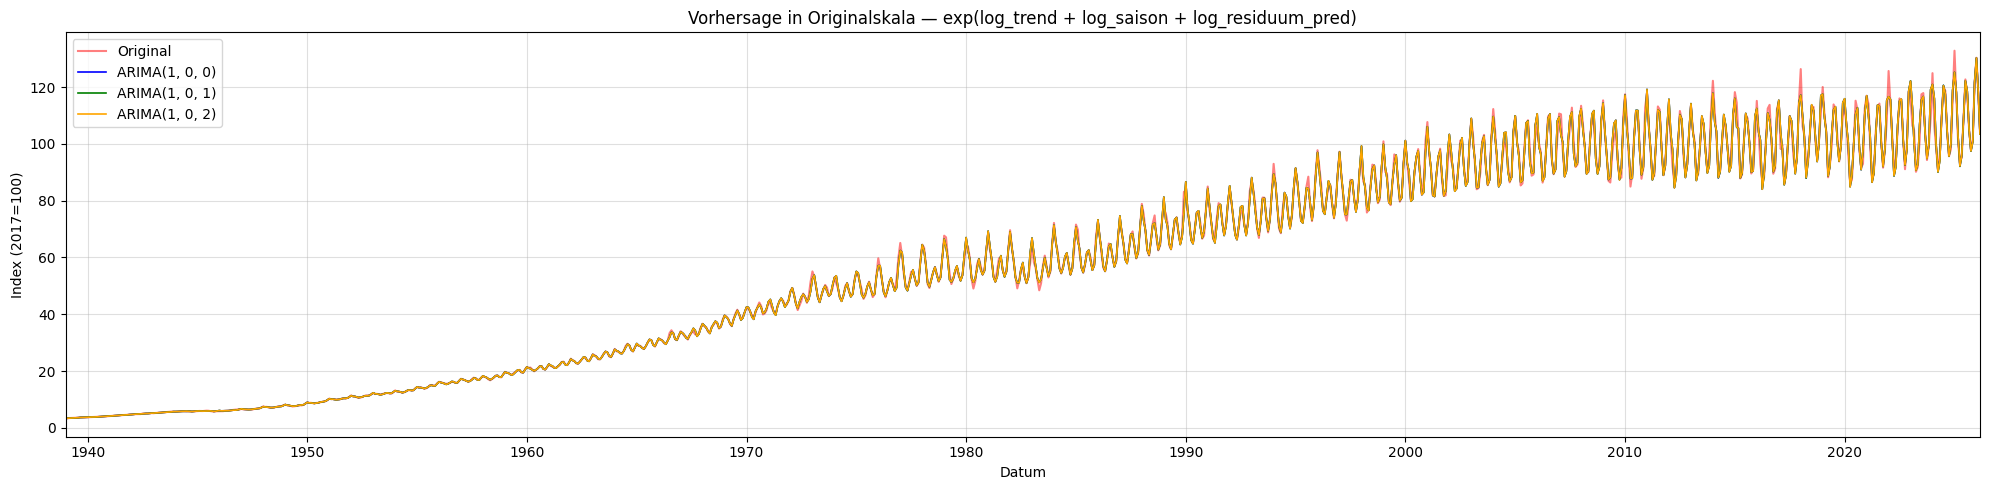

In [24]:
df_plot = df.dropna(subset=["log_trend", "log_saison", "log_residuum"]).copy()

# Rücktransformation jeder Modellvorhersage in den Originalraum
for order in candidates:
    df_plot[f"pred_orig_{order}"] = np.exp(
        df_plot["log_trend"] + df_plot["log_saison"] + results[order]["pred"]
    )

colors = {(1,0,0): "blue", (1,0,1): "green", (1,0,2): "orange"}

# --- Plot 1: Log-Residuum-Raum ---
fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(time_series.index, time_series, color="red", alpha=0.8, label="log_residuum")
for order in candidates:
    ax.plot(df_plot.index, results[order]["pred"],
            color=colors[order], linewidth=1.5, label=f"ARIMA{order}")
ax.set_title("Vorhersage im Log-Residuum-Raum (in-sample)")
ax.set_xlabel("Datum"); ax.set_ylabel("log_residuum")
ax.legend(); ax.grid(alpha=0.4); ax.margins(x=0)
plt.tight_layout()
plt.show()

# --- Plot 2: Originalskala (Rücktransformation) ---
fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(df_plot.index, df_plot["value"], color="red", alpha=0.5, label="Original")
for order in candidates:
    ax.plot(df_plot.index, df_plot[f"pred_orig_{order}"],
            color=colors[order], linewidth=1.2, label=f"ARIMA{order}")
ax.set_title("Vorhersage in Originalskala — exp(log_trend + log_saison + log_residuum_pred)")
ax.set_xlabel("Datum"); ax.set_ylabel("Index (2017=100)")
ax.legend(); ax.grid(alpha=0.4); ax.margins(x=0)
plt.tight_layout()
plt.show()

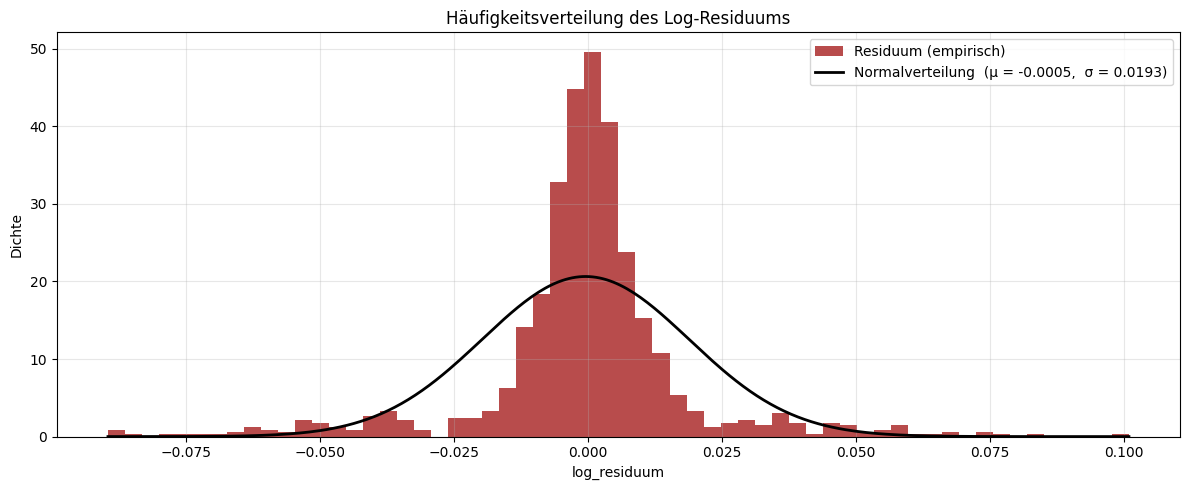

Mittelwert:          -0.000491
Standardabweichung:  0.019333
Schiefe:             -0.2715
Kurtosis:            5.4391   (Normalverteilung = 0)


In [29]:
from scipy import stats

residuum = df["log_residuum"].dropna()
mu, std  = stats.norm.fit(residuum)

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(residuum, bins=60, density=True,
        color="#9B0000", alpha=0.7, label="Residuum (empirisch)")

x = np.linspace(residuum.min(), residuum.max(), 300)
ax.plot(x, stats.norm.pdf(x, mu, std), color="black", linewidth=2,
        label=f"Normalverteilung  (μ = {mu:.4f},  σ = {std:.4f})")

ax.set_title("Häufigkeitsverteilung des Log-Residuums")
ax.set_xlabel("log_residuum")
ax.set_ylabel("Dichte")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mittelwert:          {mu:.6f}")
print(f"Standardabweichung:  {std:.6f}")
print(f"Schiefe:             {residuum.skew():.4f}")
print(f"Kurtosis:            {residuum.kurtosis():.4f}   (Normalverteilung = 0)")